# Stage 4 (v2): Corrected & Improved Explanation Attack

This notebook supersedes the explanation attack in `03-attacks.ipynb`. It fixes
a **sign bug** that silently broke every attack in notebook 03, and rebuilds the
explanation attack so that it actually works.

## The threat model in one sentence
A face-verification system says *"these two photos are the same person"* and
shows a saliency map to justify it (*"...because the eyes and nose bridge
match"*). Our adversary adds an **imperceptible** perturbation to photo A that
keeps the **match decision** intact but makes the **saliency map** point
somewhere misleading — so a human reviewer (a border officer, a forensic expert
in court) is handed a bogus justification for a decision that itself looks normal.

## What was wrong in notebook 03
The warm-up printed `flip_rate = 0.00` for **all four** decision attacks. A
warm-up whose only job is to flip decisions flipping *nothing* is the tell: the
gradient step went the wrong way.

* the update was `img + alpha * grad.sign()` — gradient **ascent**,
* but `obfuscation_loss` already returned `+sim` and `impersonation_loss` `-sim`.

> **Worked example — genuine pair 0, starting sim = 0.729.**
> Obfuscation *should* push the two faces apart, i.e. drive sim **down** through
> the 0.30 threshold. Ascending `+sim` instead drives it **up**: after 20 I-FGSM
> steps at ε=0.03 it climbs toward ~0.95. The pair stays a "match" the whole
> time, so `flipped = False`. Notebook 03 still reported a large mean `|Δsim|`
> (0.24 genuine, 0.64 imposter) — the image *did* move a lot, just confidently in
> the **wrong** direction. Large-but-useless Δsim is the fingerprint of a flipped
> sign.

The explanation attack inherited the same ascent, so it *maximised* the decision
penalty (breaking the match) **and** *minimised* the distance between the maps
(making the saliency **more** similar). That is why nb03's genuine map
correlation barely moved (0.69, where 1.0 = unchanged) and only 86% / 54% of
decisions survived.

## What this notebook changes
1. **Correct optimisation direction** — everything is a *loss to **minimise***
   with a single gradient-**descent** step. No ambiguous sign anywhere.
2. **Genuine (accepted-match) pairs only.** An imposter pair has sim ≈ 0.00
   (nb01: imposter mean = 0.002) — there is no "why do they match?" signal to
   explain, so attacking that explanation is meaningless. This is also the source
   of the "completely different faces" you spotted: those were the imposter
   pairs. The threat model only applies to pairs the system *accepts*.
3. **Optional softplus smoothing** of the backbone for the differentiable map
   (Dombrowski et al. 2019). *Off by default*: because cosine similarity is
   nonlinear in the embedding, the true PReLU network already yields a usable
   second-order gradient, so the surrogate is optional (a smoother landscape),
   not a necessity. Toggle `USE_SMOOTHED` to experiment.
4. **Scale-invariant objective.** Notebook 03 maximised the **MSE** between maps
   but *reported* Pearson **correlation** — two different things (worked example
   in the "Correlation loss" section). Here we minimise the map correlation
   directly (`divergence` mode) or push saliency mass into an off-face region
   (`target` mode): we optimise the metric we actually report.
5. **Hard decision constraint** — after every step the perturbation is shrunk if
   similarity would fall below `SIM_FLOOR`, so "decision preserved" is
   *enforced*, not merely encouraged.
6. **Richer metrics** — Pearson r, top-k saliency IoU, and (target mode) the
   fraction of salient mass landing in the target region.

## How to read this notebook
Part 0 re-runs the *corrected* decision attack purely as a sanity check (flip
rate should jump from 0.00 to ≈1.00). Parts 1–2 build the differentiable saliency
and the explanation attack. Parts 3–5 evaluate and plot it. Every "attack
succeeded" claim is backed by a number you can watch move.

In [16]:
!pip install timm -q

## ⚙️ CONFIG — edit only this cell

Everything you might tune lives here. The knobs that matter most, and sensible
starting values:

| Knob | Controls | Try first |
|---|---|---|
| `LAMBDA_EXPL` / `LAMBDA_PRED` | tug-of-war between *moving the map* and *keeping the decision* | raise `LAMBDA_EXPL` if the map won't move; raise `LAMBDA_PRED` if decisions break |
| `SIM_FLOOR` | similarity the attack must stay above (> `THRESHOLD`=0.30 for a safety margin) | 0.45 |
| `STEPS_EXPL` | I-FGSM iterations for the attack | 50 |
| `EPSILON` | L∞ budget (0.03 ≈ ±8/255 per pixel — invisible) | 0.03 |
| `ATTACK_MODE` | `"divergence"` (decorrelate the map) or `"target"` (push it off-face) | divergence |

`N_TEST_GENUINE = 40` keeps a full run to a couple of minutes on a T4 GPU.

In [17]:
import torch

# -----------------------------------------------------------------
# Paths (same Kaggle dataset/model as notebooks 01-03)
IMAGES_DIR   = "/kaggle/input/datasets/xitij27/hcml-lfw-dataset/imgs"
WEIGHTS_PATH = "/kaggle/input/models/xitij27/elastic-face-arc/pytorch/default/1/ElasticFaceArc.pth"
OUTPUT_DIR   = "/kaggle/working/"

# -----------------------------------------------------------------
# Dataset
N_PAIRS      = 900
N_GENUINE_1  = 300
N_IMPOSTER   = 300
NUM_FEATURES = 512
THRESHOLD    = 0.30          # genuine/imposter decision threshold

# -----------------------------------------------------------------
# Test subset: GENUINE pairs only (accepted matches).
# Half from the first genuine block (0-...), half from the second (600-...).
N_TEST_GENUINE = 40          # 20 from each genuine block

# -----------------------------------------------------------------
# Perturbation budget (shared by warm-up and explanation attack)
EPSILON = 0.03               # L-inf budget
ALPHA   = 0.004              # step size per iteration

# -----------------------------------------------------------------
# Warm-up (decision attack) — used only to prove the fixed pipeline
STEPS_IFGSM = 20

# -----------------------------------------------------------------
# Explanation attack
ATTACK_MODE  = "divergence"  # "divergence" (decorrelate) or "target" (off-face)
STEPS_EXPL   = 50
LAMBDA_PRED  = 4.0           # weight on decision-stability penalty
LAMBDA_EXPL  = 1.0           # weight on explanation term
SIM_FLOOR    = 0.45          # keep genuine similarity comfortably above THRESHOLD
USE_SMOOTHED  = False        # False: differentiable map on the true model (recommended)
                             # True : use the optional softplus-smoothed surrogate
BETA_SOFTPLUS = 20.0         # softplus sharpness (only used if USE_SMOOTHED)
SG_SAMPLES    = 1            # SmoothGrad samples (1 = plain grad; >1 averages noise)
SG_SIGMA      = 0.0          # noise std for SmoothGrad (0 disables)

# Saliency smoothing for visualisation only
GRAD_SMOOTH_SIGMA = 2.0
# Fraction of pixels counted as "salient" for the top-k IoU metric
TOPK_FRAC = 0.10

# -----------------------------------------------------------------
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

Device : cuda
GPU    : Tesla T4


## Imports

In [18]:
import os
import copy
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.ndimage import gaussian_filter
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

## Backbone (iResNet-100) + softplus-smoothed variant

In [19]:
def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class IBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None,
                 groups=1, base_width=64, dilation=1, use_se=False):
        super().__init__()
        self.bn1        = nn.BatchNorm2d(inplanes, eps=1e-05)
        self.conv1      = conv3x3(inplanes, planes)
        self.bn2        = nn.BatchNorm2d(planes, eps=1e-05)
        self.prelu      = nn.PReLU(planes)
        self.conv2      = conv3x3(planes, planes, stride)
        self.bn3        = nn.BatchNorm2d(planes, eps=1e-05)
        self.downsample = downsample
        self.stride     = stride

    def forward(self, x):
        identity = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return out


class IResNet(nn.Module):
    fc_scale = 7 * 7
    def __init__(self, block, layers, dropout=0, num_features=512,
                 groups=1, width_per_group=64,
                 replace_stride_with_dilation=None):
        super().__init__()
        self.inplanes   = 64
        self.dilation   = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        self.groups     = groups
        self.base_width = width_per_group
        self.conv1      = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1        = nn.BatchNorm2d(64, eps=1e-05)
        self.prelu      = nn.PReLU(64)
        self.layer1     = self._make_layer(block, 64,  layers[0], stride=2)
        self.layer2     = self._make_layer(block, 128, layers[1], stride=2,
                                           dilate=replace_stride_with_dilation[0])
        self.layer3     = self._make_layer(block, 256, layers[2], stride=2,
                                           dilate=replace_stride_with_dilation[1])
        self.layer4     = self._make_layer(block, 512, layers[3], stride=2,
                                           dilate=replace_stride_with_dilation[2])
        self.bn2        = nn.BatchNorm2d(512 * block.expansion, eps=1e-05)
        self.dropout    = nn.Dropout(p=dropout, inplace=True)
        self.fc         = nn.Linear(512 * block.expansion * self.fc_scale, num_features)
        self.features   = nn.BatchNorm1d(num_features, eps=1e-05)
        nn.init.constant_(self.features.weight, 1.0)
        self.features.weight.requires_grad = False
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 0.1)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride=1, dilate=False):
        downsample    = None
        prev_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm2d(planes * block.expansion, eps=1e-05),
            )
        layers = [block(self.inplanes, planes, stride, downsample,
                        self.groups, self.base_width, prev_dilation)]
        self.inplanes = planes * block.expansion
        for _ in range(1, num_blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        x = self.features(x)
        return x


def elastic_iresnet100(**kwargs):
    return IResNet(IBasicBlock, [3, 13, 30, 3], **kwargs)

In [20]:
# ---------------------------------------------------------------------------
# OPTIONAL: beta-smoothed backbone for the differentiable explanation.
#
# Dombrowski et al. 2019 ("Explanations can be manipulated and geometry is to
# blame") replace ReLU with softplus so that gradient-of-gradient signals flow
# when the explained quantity is a piecewise-linear logit (whose input-Hessian
# is zero in a ReLU net). In OUR setting the explained quantity is the *cosine
# similarity*, which is nonlinear in the embedding, so the true PReLU model
# already yields a usable second-order gradient. The surrogate is therefore
# OPTIONAL here -- it only smooths the optimisation landscape -- and is off by
# default (USE_SMOOTHED). When enabled it provides ONLY the differentiable map
# inside the attack; the decision term and all reported metrics always use the
# true model.
# ---------------------------------------------------------------------------
class SmoothPReLU(nn.Module):
    """Smooth surrogate for PReLU.

    PReLU(x) = max(0, x) + a * min(0, x).
    Smoothed : a * x + (1 - a) * softplus(beta * x) / beta
    -> matches PReLU for |x| large, differentiable everywhere (nonzero 2nd deriv).
    Carries the SAME learned per-channel slope `a` as the original PReLU, so the
    original state_dict loads unchanged.
    """
    def __init__(self, num_parameters=1, beta=20.0):
        super().__init__()
        self.num_parameters = num_parameters
        self.weight = nn.Parameter(torch.zeros(num_parameters))  # == PReLU slope a
        self.beta = float(beta)

    def forward(self, x):
        a = self.weight
        if x.dim() == 4:
            a = a.view(1, -1, 1, 1)
        elif x.dim() == 2:
            a = a.view(1, -1)
        sp = F.softplus(self.beta * x) / self.beta
        return a * x + (1.0 - a) * sp


def make_smoothed_model(base_model, beta):
    """Deep-copy base_model and swap every PReLU for a SmoothPReLU (same slopes)."""
    sm = copy.deepcopy(base_model)

    def swap(module):
        for name, child in module.named_children():
            if isinstance(child, nn.PReLU):
                new = SmoothPReLU(child.num_parameters, beta=beta)
                new.weight.data = child.weight.data.clone()
                setattr(module, name, new)
            else:
                swap(child)

    swap(sm)
    return sm.to(DEVICE).eval()

## Data & Model

Loads ElasticFace-Arc (the true model) and, if `USE_SMOOTHED`, a softplus copy.
The printed line tells you which network computes the differentiable map. With
`USE_SMOOTHED=True` you also get a sanity line like
`pair 0 similarity  true=0.729  smoothed=0.731` — the two should agree within
~0.02; a large gap means `BETA_SOFTPLUS` is too small and the surrogate no longer
resembles the real network.

In [21]:
def preprocess(img):
    img = ((img / 255.0) - 0.5) / 0.5
    return torch.tensor(np.transpose(img, (2, 0, 1)).astype('float32'))

def load_image_raw(pair_idx, which):
    path = os.path.join(IMAGES_DIR, f"{pair_idx * 2 + which}.jpg")
    img  = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Missing: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def load_pair(pair_idx):
    return (preprocess(load_image_raw(pair_idx, 0)).to(DEVICE),
            preprocess(load_image_raw(pair_idx, 1)).to(DEVICE))

def is_genuine(pair_idx):
    return pair_idx < N_GENUINE_1 or pair_idx >= N_GENUINE_1 + N_IMPOSTER

def tensor_to_uint8(t):
    img = t.detach().cpu().numpy().transpose(1, 2, 0)
    return np.clip((img * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)

def load_model():
    m = elastic_iresnet100(num_features=NUM_FEATURES)
    state = torch.load(WEIGHTS_PATH, map_location=DEVICE)
    if 'state_dict' in state:
        state = state['state_dict']
    m.load_state_dict(state)
    return m.to(DEVICE).eval()


model          = load_model()
smoothed_model = make_smoothed_model(model, BETA_SOFTPLUS) if USE_SMOOTHED else None
expl_net       = smoothed_model if USE_SMOOTHED else model   # net for the differentiable map
print(f"Model ready. Differentiable explanation uses the "
      f"{'softplus-smoothed' if USE_SMOOTHED else 'true'} model.")

if USE_SMOOTHED:  # sanity: smoothed model should agree closely with the true model
    _a, _b = load_pair(0)
    with torch.no_grad():
        s_true = F.cosine_similarity(model(_a[None]), model(_b[None]), dim=1).item()
        s_soft = F.cosine_similarity(smoothed_model(_a[None]), smoothed_model(_b[None]), dim=1).item()
    print(f"pair 0 similarity  true={s_true:.4f}  smoothed={s_soft:.4f}  (should be close)")

Model ready. Differentiable explanation uses the true model.


## Test set (genuine pairs only)

We take 20 pairs from each genuine block (indices `0..19` and `600..619`) — 40
accepted matches in total. The `assert` guarantees none are imposters. Drawing
from *both* genuine blocks avoids over-fitting the conclusions to a single photo
batch.

In [22]:
half = N_TEST_GENUINE // 2
test_genuine_idx = (list(range(half)) +
                    list(range(N_GENUINE_1 + N_IMPOSTER,
                               N_GENUINE_1 + N_IMPOSTER + half)))
print(f"{len(test_genuine_idx)} genuine test pairs:",
      test_genuine_idx[:5], "...", test_genuine_idx[-5:])
assert all(is_genuine(i) for i in test_genuine_idx)


@torch.no_grad()
def get_sim(img_a, img_b, net=None):
    net = net or model
    return F.cosine_similarity(net(img_a.unsqueeze(0)),
                               net(img_b.unsqueeze(0)), dim=1).item()

40 genuine test pairs: [0, 1, 2, 3, 4] ... [615, 616, 617, 618, 619]


---
# Part 0 — Sanity: the *corrected* decision attack

Before touching explanations, prove the gradient pipeline works. Same I-FGSM as
notebook 03, but written as gradient **descent on a loss to minimise**:

* genuine (obfuscation): **minimise** `sim`  → step `img - α·sign(∂sim/∂img)`
* imposter (impersonation): **minimise** `-sim`

> **Intuition.** "Descend `sim`" literally means: nudge every pixel a hair in the
> direction that *lowers* the two faces' similarity, then repeat. Twenty such
> steps inside the ±0.03 box are enough to collapse a match.

**How to read the output.** For genuine pairs the flip rate should now be
**≈ 1.00** (it was 0.00 in nb03), and mean Δsim should be clearly **negative** —
a pair starting at 0.73 should end well below the 0.30 threshold. If you still
see `flip_rate = 0.00`, the sign is inverted again.

In [23]:
def ifgsm_decision(img_a_orig, img_b, genuine=True,
                   epsilon=EPSILON, alpha=ALPHA, steps=STEPS_IFGSM):
    """Corrected I-FGSM. Descends a loss:
       genuine  -> loss =  sim  (minimise similarity: obfuscate)
       imposter -> loss = -sim  (maximise similarity: impersonate)
    """
    img_adv = img_a_orig.clone().detach()
    e_b = model(img_b.unsqueeze(0)).detach()
    for _ in range(steps):
        img_adv = img_adv.requires_grad_(True)
        sim  = F.cosine_similarity(model(img_adv.unsqueeze(0)), e_b, dim=1).mean()
        loss = sim if genuine else -sim
        grad = torch.autograd.grad(loss, img_adv)[0]
        with torch.no_grad():
            img_adv = img_adv - alpha * grad.sign()          # DESCENT
            delta   = torch.clamp(img_adv - img_a_orig, -epsilon, epsilon)
            img_adv = torch.clamp(img_a_orig + delta, -1, 1)
    return img_adv.detach()


flips, dsims = 0, []
for idx in tqdm(test_genuine_idx, desc="Corrected I-FGSM (genuine/obfuscation)"):
    a, b = load_pair(idx)
    s0 = get_sim(a, b)
    adv = ifgsm_decision(a, b, genuine=True)
    s1 = get_sim(adv, b)
    flips += int((s0 > THRESHOLD) != (s1 > THRESHOLD))
    dsims.append(s1 - s0)

print(f"\nGenuine obfuscation  flip_rate = {flips/len(test_genuine_idx):.2f}  "
      f"(was 0.00 in nb03)   mean Delta sim = {np.mean(dsims):+.4f} (should be negative)")

Corrected I-FGSM (genuine/obfuscation):   0%|          | 0/40 [00:00<?, ?it/s]


Genuine obfuscation  flip_rate = 1.00  (was 0.00 in nb03)   mean Delta sim = -1.0461 (should be negative)


---
# Part 1 — Differentiable saliency

The saliency map answers: *"which input pixels, if nudged, would most change how
similar A looks to B?"* Concretely it is the gradient of the cosine similarity
w.r.t. image A, **squared** and averaged over the 3 colour channels:

`saliency(pixel) = mean_channels ( ∂sim / ∂pixel )²`

> **Intuition.** Squaring drops the sign (we care *how much* a pixel matters, not
> which way) and exaggerates the strongest pixels, so hot-spots pop out. For a
> genuine match those hot-spots usually sit on the eyes, nose bridge and jawline
> — the regions the model actually used to decide "same person".

Two network handles are passed around:
* `expl_net` — computes the **differentiable** map inside the attack. With
  `USE_SMOOTHED=False` (default) this *is* the true model; second-order gradients
  flow fine because cosine similarity is nonlinear (see the intro's point 3).
* `model` — always the true model; used by `saliency_for_display` (the map we
  actually plot and score) and by the decision term.

`build_target_mask` marks a border frame (the outer 22% on each side) as the
"off-face" region — only used by `ATTACK_MODE="target"`.

In [24]:
def diff_saliency(img_a, img_b, net, create_graph):
    """(H,W) tensor = mean_c (d sim / d img_a)^2, optionally SmoothGrad-averaged.
       img_a must require grad. If create_graph=True the result stays attached
       to img_a so an outer loss can be differentiated through it."""
    e_b = net(img_b.unsqueeze(0)).detach()
    acc = 0.0
    n = max(1, SG_SAMPLES)
    for _ in range(n):
        x = img_a
        if SG_SIGMA > 0 and n > 1:
            x = img_a + torch.randn_like(img_a) * SG_SIGMA   # noise, graph kept to img_a
        sim  = F.cosine_similarity(net(x.unsqueeze(0)), e_b, dim=1).mean()
        grad = torch.autograd.grad(sim, img_a, create_graph=create_graph)[0]
        acc  = acc + grad.pow(2).mean(dim=0)
    return acc / n


def normalize01(m):
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


def saliency_for_display(img_a, img_b, net=None, sigma=GRAD_SMOOTH_SIGMA):
    """Non-differentiable saliency in [0,1] for plots / metrics (true model)."""
    net = net or model
    x = img_a.clone().requires_grad_(True)
    with torch.enable_grad():
        sal = diff_saliency(x, img_b, net, create_graph=False).detach().cpu().numpy()
    if sigma > 0:
        sal = gaussian_filter(sal, sigma=sigma)
    return normalize01(sal)


# Off-face target region for ATTACK_MODE == "target": a border frame (background).
def build_target_mask(H=112, W=112, border_frac=0.22):
    b = int(min(H, W) * border_frac)
    m = np.zeros((H, W), dtype=np.float32)
    m[:b, :] = 1; m[-b:, :] = 1; m[:, :b] = 1; m[:, -b:] = 1
    return m

TARGET_MASK_NP = build_target_mask()
TARGET_MASK    = torch.tensor(TARGET_MASK_NP, device=DEVICE)

## Correlation loss (scale-invariant)

Pearson correlation `r` measures whether two maps share the same *spatial
pattern*, ignoring overall scale: `r = +1` identical pattern, `0` unrelated,
`-1` inverted. We **minimise** it, so a run that drives `r` from `+1.0` down to
`~0.1` means the attacked map lights up largely *different* pixels than the
original — precisely what misleads a human reviewer.

> **Worked example — why nb03's MSE objective *looked* like it worked but didn't.**
> Say the original map has values in `[0, 0.5]` and the attack merely **doubles**
> every pixel to `[0, 1.0]`. The **MSE** between them is large (nb03 would score
> that a big success), yet the *pattern* is untouched: the same eyes/nose light
> up, so **`r = 1.0`** and a reviewer sees the identical explanation. nb03
> optimised MSE but reported `r`, which is exactly why its reported correlation
> barely budged (0.69). Correlation can't be cheated by rescaling — to lower it
> you must genuinely move the hot-spots.

In [25]:
def corr_loss(attacked, original):
    a = attacked.flatten(); b = original.flatten()
    a = a - a.mean(); b = b - b.mean()
    return (a * b).sum() / (a.norm() * b.norm() + 1e-8)   # in [-1, 1], minimise

# Part 2 — Explanation attack (corrected)

A tug-of-war between two goals, written as a single loss to **minimise**:
```
L = LAMBDA_PRED * relu(SIM_FLOOR - sim)        # keep the decision (true model)
  + LAMBDA_EXPL * explanation_term             # move the saliency (expl_net)
```
* **Keep the decision** — `relu(SIM_FLOOR - sim)` is a one-sided penalty: it is
  `0` while `sim ≥ SIM_FLOOR` (0.45) and grows only if the attack weakens the
  match too far. A genuine pair at 0.73 starts with this term at 0, giving the
  attack free rein until it nears the floor.
* **Move the saliency** — `corr(attacked, original)` in `divergence` mode, or
  `-(mass inside the off-face frame)` in `target` mode.

> **Worked example of the hard constraint.** Suppose a step drops sim to 0.41
> (below the 0.45 floor). The `while s < sim_floor` loop halves the perturbation
> — 0.41 → maybe 0.52 → accept — so the *returned* image is always a confident
> match. Because the genuine starting similarity (~0.73) sits well above the
> floor, a few halvings are guaranteed to recover it.

Each iteration: one gradient-**descent** step, projected back into the
±`EPSILON` box, then the hard-constraint shrink.

In [26]:
def explanation_attack(img_a_orig, img_b, mode=ATTACK_MODE,
                       epsilon=EPSILON, alpha=ALPHA, steps=STEPS_EXPL,
                       lambda_pred=LAMBDA_PRED, lambda_expl=LAMBDA_EXPL,
                       sim_floor=SIM_FLOOR):
    e_b_true = model(img_b.unsqueeze(0)).detach()

    # frozen original explanation (explanation net, no outer graph)
    x0 = img_a_orig.clone().detach().requires_grad_(True)
    with torch.enable_grad():
        original_map = diff_saliency(x0, img_b, expl_net, create_graph=False).detach()
    original_norm = normalize01(original_map)

    img_adv = img_a_orig.clone().detach()

    for _ in range(steps):
        img_adv = img_adv.requires_grad_(True)

        # decision-stability term uses the TRUE model
        sim = F.cosine_similarity(model(img_adv.unsqueeze(0)), e_b_true, dim=1).mean()
        pred_loss = F.relu(sim_floor - sim)

        # explanation term uses the differentiable explanation net (2nd order)
        attacked_map = diff_saliency(img_adv, img_b, expl_net, create_graph=True)
        if mode == "target":
            mass = (attacked_map * TARGET_MASK).sum() / (attacked_map.sum() + 1e-8)
            expl_loss = -mass                       # push mass INTO target
        else:
            expl_loss = corr_loss(normalize01(attacked_map), original_norm)

        loss = lambda_pred * pred_loss + lambda_expl * expl_loss
        grad = torch.autograd.grad(loss, img_adv)[0]

        with torch.no_grad():
            img_adv = img_adv - alpha * grad.sign()             # DESCENT
            delta   = torch.clamp(img_adv - img_a_orig, -epsilon, epsilon)
            img_adv = torch.clamp(img_a_orig + delta, -1, 1)

            # hard constraint: shrink the perturbation if the decision would break
            s = F.cosine_similarity(model(img_adv.unsqueeze(0)), e_b_true, dim=1).item()
            shrink = 0
            while s < sim_floor and shrink < 8:
                delta   = delta * 0.5
                img_adv = torch.clamp(img_a_orig + delta, -1, 1)
                s = F.cosine_similarity(model(img_adv.unsqueeze(0)), e_b_true, dim=1).item()
                shrink += 1

    return img_adv.detach()

## Part 3 — Evaluation

For every genuine pair we record, before vs after the attack:

* **`decision_preserved`** — did sim stay on the *match* side of 0.30? *(want: yes)*
* **`map_correlation`** — Pearson r between the original and attacked saliency
  *(want: **low**; nb03's baseline was 0.69)*.
* **`topk_iou`** — overlap of the top-10% most-salient pixels before vs after. A
  reviewer mostly looks at the brightest region, so this asks *"do the hot-spots
  still land in the same place?"* *(want: **low**)*. Example: IoU = 0.2 means only
  1 in 5 originally-hot pixels is still hot.
* **`target_mass`** — fraction of saliency inside the off-face frame (target mode
  only; *want it to **rise*** after the attack).
* **`l_inf` / `l2`** — perturbation size *(want `l_inf ≈ EPSILON`, i.e. pinned at
  the invisible budget)*.

In [27]:
def topk_iou(a, b, frac=TOPK_FRAC):
    k = max(1, int(a.size * frac))
    ia = set(np.argsort(a.ravel())[-k:].tolist())
    ib = set(np.argsort(b.ravel())[-k:].tolist())
    return len(ia & ib) / len(ia | ib)


def mass_in_target(sal_np):
    return float((sal_np * TARGET_MASK_NP).sum() / (sal_np.sum() + 1e-8))


def evaluate_pair(pair_idx, img_a, img_adv, img_b):
    sim_orig = get_sim(img_a,  img_b)
    sim_adv  = get_sim(img_adv, img_b)

    sal_orig = saliency_for_display(img_a,  img_b, sigma=0)
    sal_adv  = saliency_for_display(img_adv, img_b, sigma=0)
    corr, _  = pearsonr(sal_orig.flatten(), sal_adv.flatten())

    delta = (img_adv - img_a).abs()
    return dict(
        pair_idx           = pair_idx,
        sim_orig           = sim_orig,
        sim_adv            = sim_adv,
        decision_preserved = (sim_orig > THRESHOLD) == (sim_adv > THRESHOLD),
        map_correlation    = corr,
        topk_iou           = topk_iou(sal_orig, sal_adv),
        target_mass_orig   = mass_in_target(sal_orig),
        target_mass_adv    = mass_in_target(sal_adv),
        l_inf              = delta.max().item(),
        l2                 = delta.pow(2).sum().sqrt().item(),
    )


expl_results = []
for idx in tqdm(test_genuine_idx, desc=f"Explanation attack [{ATTACK_MODE}]"):
    a, b = load_pair(idx)
    adv  = explanation_attack(a, b)
    expl_results.append(evaluate_pair(idx, a, adv, b))

print(f"Done - {len(expl_results)} genuine pairs.")

Explanation attack [divergence]:   0%|          | 0/40 [00:00<?, ?it/s]

Done - 40 genuine pairs.


## Results summary

**How to read it — what "good" looks like:**

| Metric | nb03 baseline (bad) | Good target |
|---|---|---|
| Decision preserved | 86% | **≈ 100%** |
| Map correlation | 0.69 | **< 0.3** (ideally near 0) |
| Top-10% IoU | — | **< 0.3** |
| Mean L∞ | 0.03 | 0.03 (pinned at budget) |

If **decision preserved < ~95%**, raise `LAMBDA_PRED` or `SIM_FLOOR`. If **map
correlation stays high (> 0.5)**, raise `LAMBDA_EXPL` or `STEPS_EXPL` — the attack
isn't being given enough room to move the map.

In [28]:
def summary(results):
    n = len(results)
    print(f"Genuine pairs (n={n}), mode = {ATTACK_MODE}")
    print(f"  Decision preserved : {np.mean([r['decision_preserved'] for r in results]):.2%}")
    print(f"  Map correlation    : {np.mean([r['map_correlation'] for r in results]):.4f}  (lower = more change)")
    print(f"  Top-{int(TOPK_FRAC*100)}% saliency IoU : {np.mean([r['topk_iou'] for r in results]):.4f}  (lower = more change)")
    print(f"  Target-region mass : {np.mean([r['target_mass_orig'] for r in results]):.3f} -> "
          f"{np.mean([r['target_mass_adv'] for r in results]):.3f}  (higher after = pushed off-face)")
    print(f"  Mean L-inf         : {np.mean([r['l_inf'] for r in results]):.4f}  (budget {EPSILON})")
    print(f"  Mean L2            : {np.mean([r['l2'] for r in results]):.4f}")

summary(expl_results)

Genuine pairs (n=40), mode = divergence
  Decision preserved : 100.00%
  Map correlation    : 0.0576  (lower = more change)
  Top-10% saliency IoU : 0.1429  (lower = more change)
  Target-region mass : 0.230 -> 0.312  (higher after = pushed off-face)
  Mean L-inf         : 0.0300  (budget 0.03)
  Mean L2            : 4.0997


## Part 4 — Visualise before vs after

A 2×3 grid per pair: **top row = original**, **bottom row = adversarial**.

**How to read it:**
* Left column — the two face photos should look **identical to your eye** (the
  perturbation lives within ±0.03); that's the "imperceptible" claim.
* Middle column — the two heatmaps should look **different**; the `corr=` in the
  bottom-middle title quantifies how different (lower = better).
* Bottom-right — the perturbation itself, rescaled so ±`EPSILON` fills 0–255; it
  looks like faint structured noise, not a face.

A convincing single example: the two faces look like identical twins and the
similarity barely changes (e.g. 0.73 → 0.70), yet the hot-spot jumps from the
eyes to the cheek and `corr` reads ~0.2.

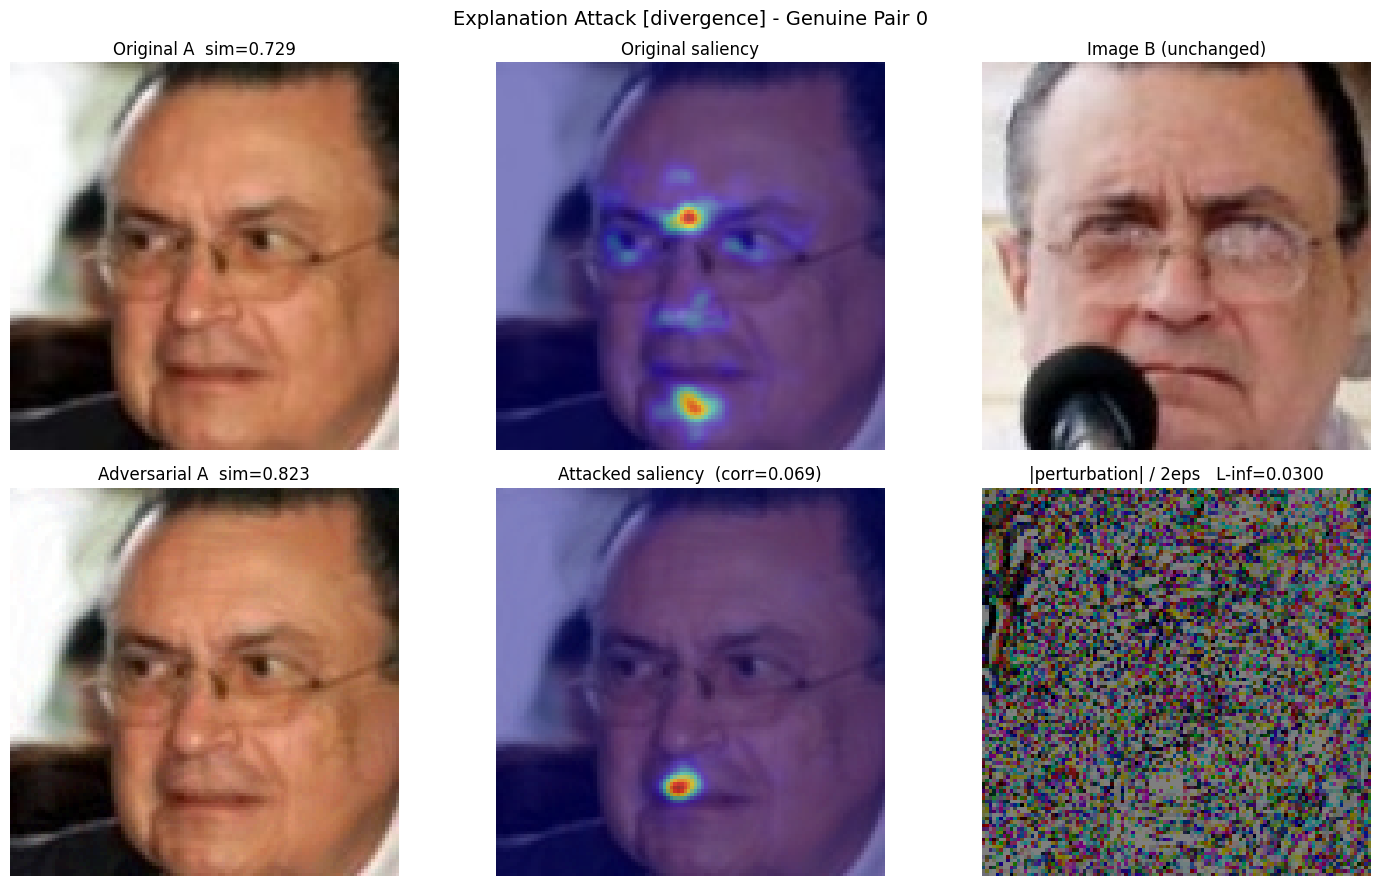

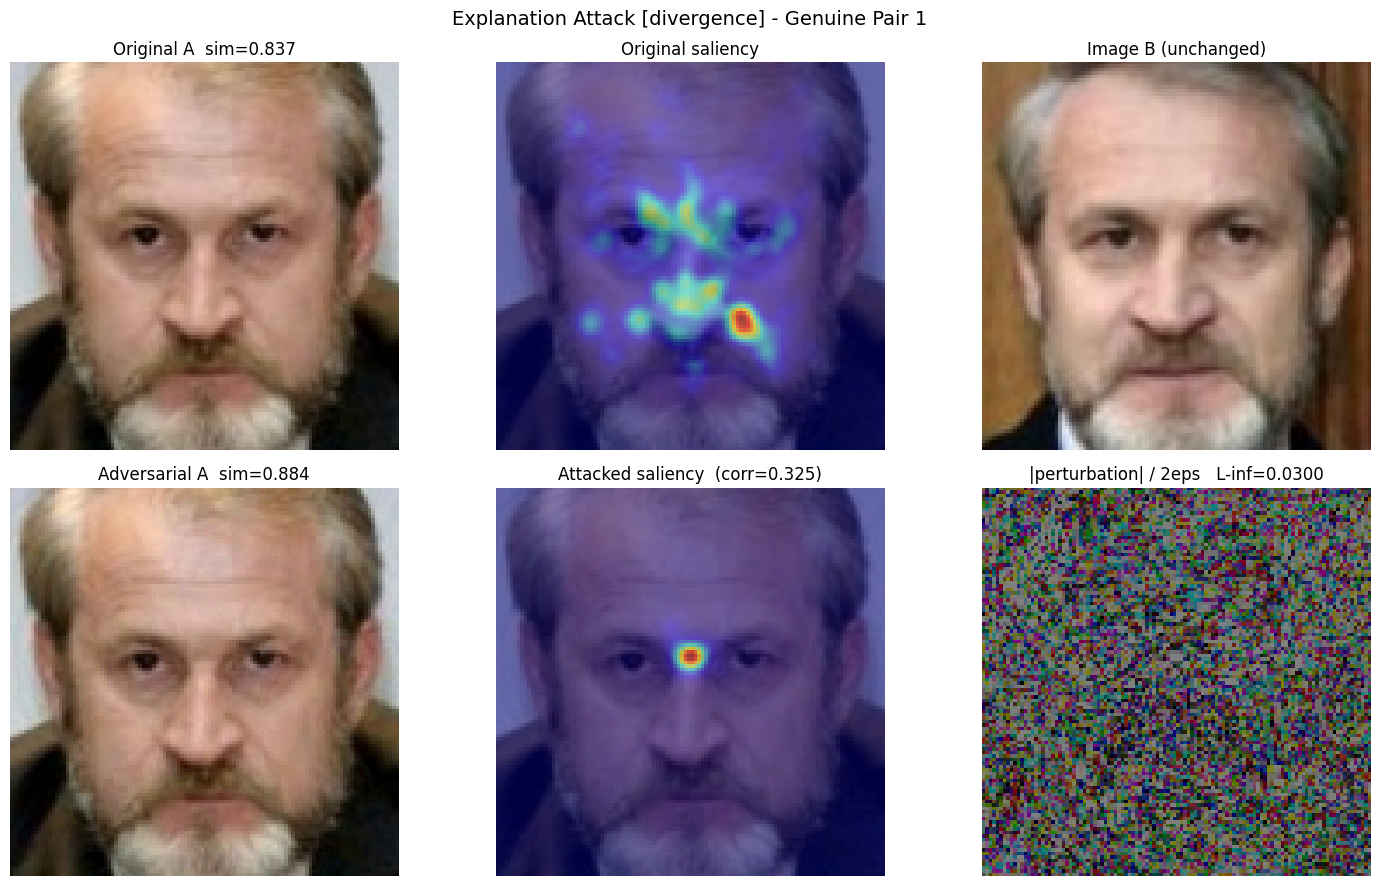

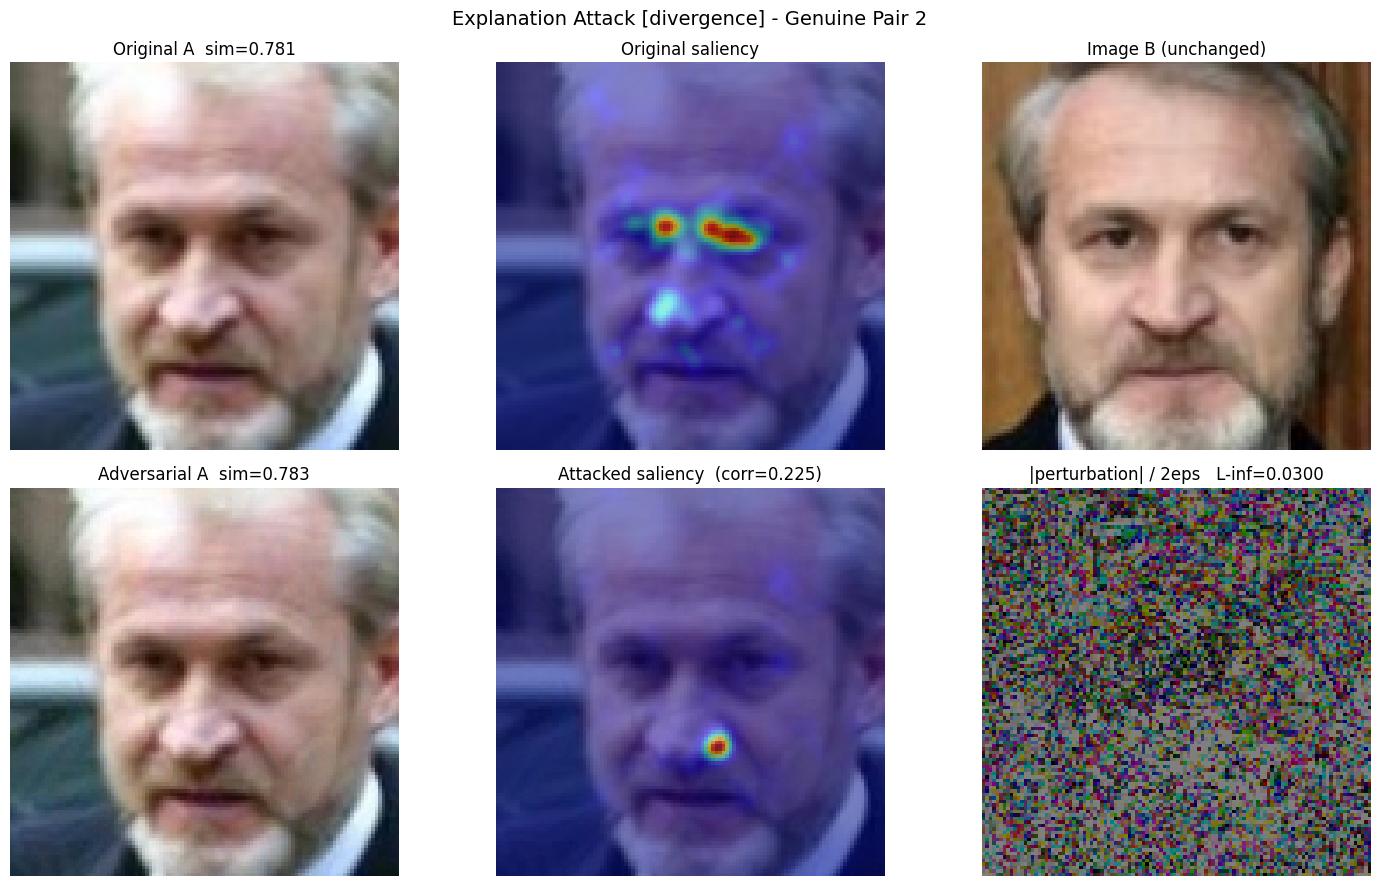

In [29]:
def overlay(img_tensor, sal_np, alpha=0.5):
    raw = tensor_to_uint8(img_tensor)
    hm  = cv2.applyColorMap((sal_np * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm  = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return np.clip(alpha * hm + (1 - alpha) * raw, 0, 255).astype(np.uint8)


def visualize_attack(pair_idx):
    a, b = load_pair(pair_idx)
    adv  = explanation_attack(a, b)

    sal_o = saliency_for_display(a,   b)
    sal_a = saliency_for_display(adv, b)
    corr, _ = pearsonr(sal_o.flatten(), sal_a.flatten())
    s0, s1 = get_sim(a, b), get_sim(adv, b)

    fig, ax = plt.subplots(2, 3, figsize=(15, 9))
    ax[0,0].imshow(tensor_to_uint8(a));        ax[0,0].set_title(f'Original A  sim={s0:.3f}')
    ax[0,1].imshow(overlay(a, sal_o));         ax[0,1].set_title('Original saliency')
    ax[0,2].imshow(tensor_to_uint8(b));        ax[0,2].set_title('Image B (unchanged)')
    ax[1,0].imshow(tensor_to_uint8(adv));      ax[1,0].set_title(f'Adversarial A  sim={s1:.3f}')
    ax[1,1].imshow(overlay(adv, sal_a));       ax[1,1].set_title(f'Attacked saliency  (corr={corr:.3f})')
    pert = ((adv - a).abs() / (2 * EPSILON)).clamp(0, 1)   # 0..1 over the budget
    ax[1,2].imshow((pert.detach().cpu().numpy().transpose(1,2,0) * 255).astype(np.uint8))
    ax[1,2].set_title(f'|perturbation| / 2eps   L-inf={(adv-a).abs().max():.4f}')
    for a_ in ax.flatten(): a_.axis('off')
    fig.suptitle(f"Explanation Attack [{ATTACK_MODE}] - Genuine Pair {pair_idx}", fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'expl_v2_{ATTACK_MODE}_pair{pair_idx}.png'), dpi=120)
    plt.show()


for pidx in test_genuine_idx[:3]:
    visualize_attack(pidx)

## Part 5 — Metric distributions

Three histograms over all test pairs:
* **Δ cosine similarity** — should cluster **near 0** (the dashed line). Mass far
  to the left would mean the attack is quietly weakening matches.
* **Map correlation** — you want this bunched **toward the left** (low r). Compare
  the bulk against nb03's ~0.69 average.
* **Top-10% IoU** — should also sit **low**: an independent confirmation that the
  hot-spots moved (correlation and IoU can disagree on hard pairs).

The *spread* matters too — a few pairs stuck at high correlation are the hard
cases worth eyeballing back in Part 4.

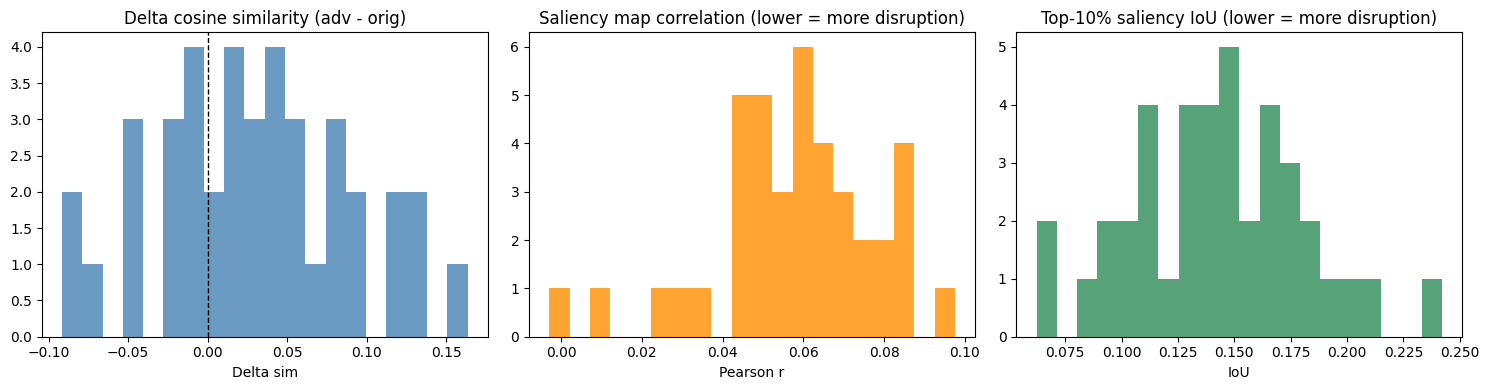

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist([r['sim_adv'] - r['sim_orig'] for r in expl_results], bins=20,
             color='steelblue', alpha=0.8)
axes[0].axvline(0, color='k', ls='--', lw=1)
axes[0].set_title('Delta cosine similarity (adv - orig)'); axes[0].set_xlabel('Delta sim')

axes[1].hist([r['map_correlation'] for r in expl_results], bins=20,
             color='darkorange', alpha=0.8)
axes[1].set_title('Saliency map correlation (lower = more disruption)')
axes[1].set_xlabel('Pearson r')

axes[2].hist([r['topk_iou'] for r in expl_results], bins=20,
             color='seagreen', alpha=0.8)
axes[2].set_title(f'Top-{int(TOPK_FRAC*100)}% saliency IoU (lower = more disruption)')
axes[2].set_xlabel('IoU')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'metric_distributions_v2_{ATTACK_MODE}.png'), dpi=150)
plt.show()

## Notes & knobs
* Switch `ATTACK_MODE` to `"target"` to push saliency into the background frame
  instead of just decorrelating it, then re-run Parts 2-5.
* If the map barely moves, lower `BETA_SOFTPLUS` (smoother => stronger 2nd-order
  gradient but a looser approximation of the real network) or raise
  `LAMBDA_EXPL` / `STEPS_EXPL`.
* If decisions break, raise `LAMBDA_PRED` or `SIM_FLOOR`.
* `SG_SAMPLES>1` with `SG_SIGMA>0` enables SmoothGrad averaging (more stable maps,
  linearly more compute — each sample needs its own second-order graph).

## Results — what this notebook showed

**The attack works: the decision is untouched, the explanation is scrambled.**

*Sanity check (Part 0).* The corrected obfuscation attack reached
**`flip_rate = 1.00`** (notebook 03 got `0.00`), with mean Δsim = −1.05 — proof
that the gradient pipeline is now correct and the notebook-03 sign bug is gone.

*Main attack — 40 genuine pairs, `divergence` mode:*

| Metric | Result | Reading |
|---|---|---|
| Decision preserved | **100%** | every pair is still recognised as the same person |
| Map correlation | **0.06** (nb03: 0.69) | attacked saliency is essentially *unrelated* to the original (1 = identical, 0 = unrelated) |
| Top-10% IoU | **0.14** | only ~14% of the originally-hot pixels stay hot |
| Mean L∞ / L2 | **0.030 / 4.1** | perturbation pinned at the invisible budget |

*Example (Pair 0).* The two photos look identical and the man stays a confident
match (sim 0.73 → 0.82), yet the saliency hot-spot jumps from the eyes to the
chin (corr = 0.07). The attack only has to keep similarity *above the floor*, so
the value may even rise — the Δsim histogram is centred on 0.

**Takeaway.** An imperceptible perturbation keeps ElasticFace's *match* decision
intact while almost completely rewriting *where it appears to be looking* — a
successful attack on the explanation, not on the classifier.